# 13. View factors and enclosures

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 12

Chapter 12 described how one surface emits. Inside a furnace, a kiln or a cabinet, every
surface also receives what the others emit and reflect, and the heat each one gains or loses
depends on how well the surfaces see one another. This chapter treats such *enclosures*. Two
ideas carry it. The *view factor* is the fraction of the radiation leaving one surface that
reaches another; it depends only on geometry. The *radiosity* is everything that leaves a
surface, emitted plus reflected; for diffuse grey surfaces it turns an enclosure into a
network of resistances, as conduction did in Chapter 1.

The engineering question is an electric furnace for hardening steel parts. Its heating
elements cover the roof and the parts lie on the hearth; the side walls are lined with
ceramic fibre and are not heated at all. Yet they carry most of the heat to the load: they
absorb radiation from the roof and send it down again. How much power reaches the load, how
long does a batch take to heat to 850 °C, and what do the walls contribute? A second
question concerns vacuum furnaces, which cannot use fibre linings and keep their heat in
with stacked metal sheets, *radiation shields*: how many are needed? The checks compute
view factors by Monte Carlo ray tracing and by numerical integration, and trace bundles of
radiation through the whole furnace.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

from scipy.integrate import solve_ivp

try:
    from engtransport import radiation, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import radiation, reference
from engtransport.numerics import bisect
from engtransport.plotting import panel_label, use_style

use_style()
SIGMA = radiation.SIGMA_SB

## 13.1 The view factor

Consider two small surface elements $dA_1$ and $dA_2$ a distance $r$ apart, whose normals
make angles $\theta_1$ and $\theta_2$ with the line joining them. A diffuse surface emits
with the same intensity in every direction, so the power leaving $dA_1$ towards $dA_2$ is
proportional to the area $dA_1\cos\theta_1$ that $dA_1$ presents in that direction and to
the solid angle $dA_2\cos\theta_2/r^2$ that $dA_2$ fills. Dividing by the total that leaves
$dA_1$, $\pi$ times the intensity times $dA_1$, and integrating over both surfaces gives the
*view factor*, the fraction of the radiation leaving surface 1 that arrives at surface 2:

$$
F_{12} = \frac{1}{A_1}\int_{A_1}\int_{A_2} \frac{\cos\theta_1\cos\theta_2}{\pi r^2}\,dA_2\,dA_1 .
\tag{13.1}
$$

The integrand is symmetric in the two surfaces, so

$$
A_1 F_{12} = A_2 F_{21} ,
\tag{13.2}
$$

the *reciprocity* rule. The product $A_iF_{ij}$ is the *exchange area*. In an enclosure of
$N$ surfaces, all the radiation leaving surface $i$ arrives somewhere, which gives the
*summation* rule

$$
\sum_{j=1}^N F_{ij} = 1 ,
\tag{13.3}
$$

where $F_{ii}$ is zero for a flat or convex surface and positive for a concave one, which
sees itself. Of the $N^2$ view factors of an enclosure, Eqs. (13.2) and (13.3) fix all but
$N(N-1)/2$; those few must come from geometry.

## 13.2 Finding view factors

The integral (13.1) has been worked out in closed form for many shapes, and catalogues of
the results exist. Three are used in this chapter. For two coaxial parallel disks of radii
$r_1$ and $r_2$ a distance $L$ apart, with $R_i = r_i/L$,

$$
F_{12} = \frac{1}{2}\left[S - \sqrt{S^2 - 4(r_2/r_1)^2}\right] , \qquad
S = 1 + \frac{1 + R_2^2}{R_1^2} .
\tag{13.4}
$$

For two equal rectangles $a \times b$ facing each other a distance $c$ apart, with
$X = a/c$ and $Y = b/c$ (Hamilton and Morgan 1952),

$$
F_{12} = \frac{2}{\pi XY}\left[\ln\sqrt{\frac{(1+X^2)(1+Y^2)}{1+X^2+Y^2}}
+ X\sqrt{1+Y^2}\arctan\frac{X}{\sqrt{1+Y^2}} + Y\sqrt{1+X^2}\arctan\frac{Y}{\sqrt{1+X^2}}
- X\arctan X - Y\arctan Y\right] .
\tag{13.5}
$$

For two rectangles at right angles sharing an edge of length $l$, with surface 1 extending
a width $w_1$ from the edge and surface 2 a width $w_2$, $W = w_1/l$ and $H = w_2/l$,

$$
\begin{aligned}
\pi W F_{12} = {}& W\arctan\frac{1}{W} + H\arctan\frac{1}{H}
- \sqrt{H^2+W^2}\,\arctan\frac{1}{\sqrt{H^2+W^2}} \\
&+ \frac{1}{4}\ln\left\{\frac{(1+W^2)(1+H^2)}{1+W^2+H^2}
\left[\frac{W^2(1+W^2+H^2)}{(1+W^2)(W^2+H^2)}\right]^{W^2}
\left[\frac{H^2(1+W^2+H^2)}{(1+H^2)(W^2+H^2)}\right]^{H^2}\right\} .
\end{aligned}
\tag{13.6}
$$

*View-factor algebra* builds other shapes from these. If surface 2 is split into parts
$2a$ and $2b$, then $F_{1,2} = F_{1,2a} + F_{1,2b}$; with reciprocity this gives, for
instance, the view factor from a roof to a horizontal band of a side wall as the difference
of two factors of the form (13.6). For long surfaces whose cross-section does not change
along their length, a two-dimensional rule does the whole job. Stretch imaginary strings
between the end points of two surfaces, $L_1$ wide; then

$$
F_{12} = \frac{(\text{sum of the crossed strings}) - (\text{sum of the uncrossed strings})}{2L_1} ,
\tag{13.7}
$$

Hottel's *crossed-string rule*, valid for any unobstructed pair of surfaces in two
dimensions (for curved or partly blocked ones, the strings are pulled taut around the
obstacles).

The furnace chamber is a box 0.8 m wide, 1.2 m deep and 0.6 m high, with the heating
elements on the roof and the load on the hearth. Its six faces need $6 \times 5/2 = 15$
independent view factors: three pairs of opposite faces from Eq. (13.5) and twelve pairs of
adjacent faces from Eq. (13.6) (`radiation.box_view_factors`).

In [2]:
Lx, Ly, Lz = 0.8, 1.2, 0.6                       # chamber width, depth and height (m)
A6, F6 = radiation.box_view_factors(Lx, Ly, Lz)
print("faces:", ", ".join(radiation.BOX_FACES))
print("areas (m2):", " ".join(f"{a:.2f}" for a in A6))
print("view factors F_ij (row i = from face i):")
for name, row in zip(radiation.BOX_FACES, F6):
    print(f"  {name:6s}", " ".join(f"{f:.4f}" for f in row), f"  sum {row.sum():.15f}")
AF = A6[:, None] * F6
print(f"largest reciprocity defect |A_i F_ij - A_j F_ji|: {np.abs(AF - AF.T).max():.1e} m2")

# three zones for the furnace: 0 heater (roof), 1 load (hearth), 2 the four walls together
A3 = np.array([A6[1], A6[0], A6[2:].sum()])
F3 = np.zeros((3, 3))
F3[0, 1], F3[1, 0] = F6[1, 0], F6[0, 1]
F3[0, 2], F3[1, 2] = 1 - F3[0, 1], 1 - F3[1, 0]
F3[2, :2] = A3[:2] * F3[:2, 2] / A3[2]          # reciprocity
F3[2, 2] = 1 - F3[2, 0] - F3[2, 1]               # summation: the walls see each other
print(f"roof to hearth {F3[0, 1]:.4f}, roof to walls {F3[0, 2]:.4f}, walls to walls {F3[2, 2]:.4f}")

faces: floor, roof, x=0, x=Lx, y=0, y=Ly
areas (m2): 0.96 0.96 0.72 0.72 0.48 0.48
view factors F_ij (row i = from face i):
  floor  0.0000 0.3417 0.1995 0.1995 0.1296 0.1296   sum 1.000000000000000
  roof   0.3417 0.0000 0.1995 0.1995 0.1296 0.1296   sum 1.000000000000000
  x=0    0.2660 0.2660 0.0000 0.2049 0.1315 0.1315   sum 1.000000000000000
  x=Lx   0.2660 0.2660 0.2049 0.0000 0.1315 0.1315   sum 1.000000000000000
  y=0    0.2592 0.2592 0.1972 0.1972 0.0000 0.0871   sum 1.000000000000000
  y=Ly   0.2592 0.2592 0.1972 0.1972 0.0871 0.0000   sum 1.000000000000000
largest reciprocity defect |A_i F_ij - A_j F_ji|: 5.6e-17 m2
roof to hearth 0.3417, roof to walls 0.6583, walls to walls 0.4734


Every row of the matrix sums to one within $10^{-15}$. Equations (13.5) and (13.6) are
separate results and nothing in their derivation forces the rows of a box to close, so this
is already a good check on both. The roof sees only 34 % of its radiation land directly on
the hearth; 66 % goes to the walls, and the walls see 47 % of their own emission land on
other walls.

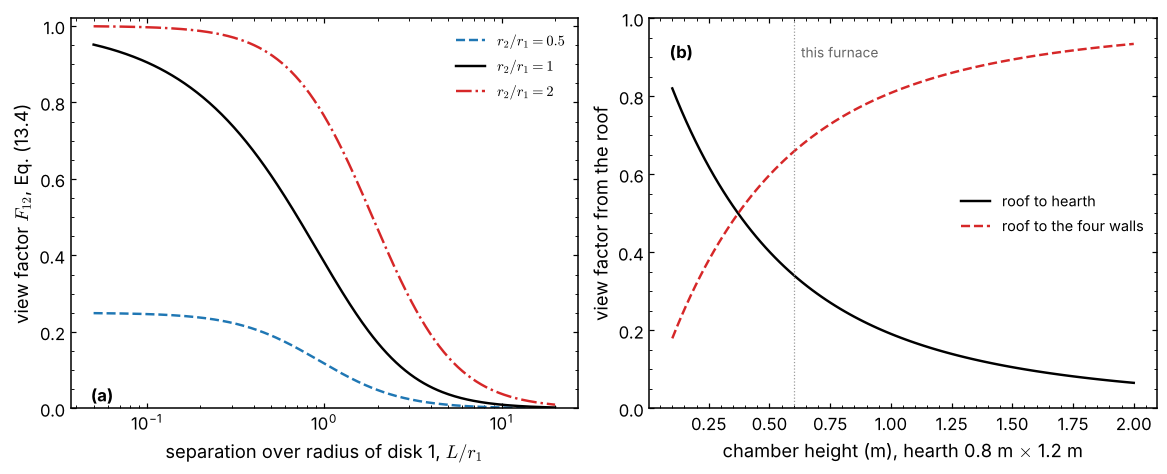

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
LoR = np.geomspace(0.05, 20.0, 300)
for ratio, style in ((0.5, "C0--"), (1.0, "k-"), (2.0, "C3-.")):
    ax1.semilogx(LoR, [radiation.view_factor_coaxial_disks(1.0, ratio, L) for L in LoR], style,
                 label=fr"$r_2/r_1 = {ratio:g}$")
ax1.set_xlabel(r"separation over radius of disk 1, $L/r_1$")
ax1.set_ylabel(r"view factor $F_{12}$, Eq. (13.4)")
ax1.set_ylim(0, 1.02)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.06)

H = np.linspace(0.1, 2.0, 100)
F_rf = np.array([radiation.view_factor_parallel_rectangles(Lx, Ly, h) for h in H])
ax2.plot(H, F_rf, "k-", label="roof to hearth")
ax2.plot(H, 1 - F_rf, "C3--", label="roof to the four walls")
ax2.axvline(Lz, color="0.6", ls=":", lw=0.8)
ax2.text(Lz + 0.03, 0.9, "this furnace", color="0.4", fontsize=9)
ax2.set_xlabel(r"chamber height (m), hearth 0.8 m $\times$ 1.2 m")
ax2.set_ylabel("view factor from the roof")
ax2.set_ylim(0, 1)
ax2.legend(loc="center right")
panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 13.1.** (a) View factor between coaxial parallel disks, Eq. (13.4), against their
separation. (b) View factors from the roof of a chamber with a 0.8 m × 1.2 m hearth to the
hearth, Eq. (13.5), and to the four walls, by summation, against the chamber height.

Two disks of equal radius see each other completely when they touch and hardly at all when
they are a few radii apart. A disk facing a larger one sees more of it, and one facing a
smaller one less, as reciprocity requires. In a chamber as high as it is narrow, the roof
sends most of its radiation to the walls; only very low chambers send most of it straight
down.

## 13.3 Radiosity and the grey enclosure

Let every surface be *diffuse* (it emits and reflects equally in all directions), *grey*
(its emissivity does not depend on wavelength, so that $\alpha = \varepsilon$) and opaque,
and let each have uniform temperature and uniform irradiation $G$, the power arriving per
unit area. The power leaving per unit area is the *radiosity*,
$J = \varepsilon E_b + (1-\varepsilon)G$, with $E_b = \sigma T^4$. The net rate of heat
leaving the surface is what leaves minus what arrives, $Q = A(J - G)$; eliminating $G$,

$$
Q = \frac{E_b - J}{(1-\varepsilon)/(\varepsilon A)} .
\tag{13.8}
$$

The difference $E_b - J$ drives the heat through a *surface resistance*
$(1-\varepsilon)/\varepsilon A$, which vanishes for a black surface. The irradiation of
surface $i$ is what all the surfaces send to it: $A_iG_i = \sum_j A_jF_{ji}J_j =
A_i\sum_jF_{ij}J_j$ by reciprocity. With the summation rule, the net rate becomes

$$
Q_i = \sum_j A_iF_{ij}\,(J_i - J_j) ,
\tag{13.9}
$$

a sum of currents through *space resistances* $1/A_iF_{ij}$ between the radiosity nodes.
Oppenheim (1956) drew this as an electrical network: each surface is a node $J_i$, joined
to its own potential $E_{bi}$ through the surface resistance and to every other node
through a space resistance. For each surface either the temperature or the net heat flow is
known, and the network gives one linear equation per surface:

$$
J_i - (1-\varepsilon_i)\sum_j F_{ij}J_j = \varepsilon_i\sigma T_i^4 \quad (T_i \text{ known}),
\qquad
J_i - \sum_j F_{ij}J_j = \frac{Q_i}{A_i} \quad (Q_i \text{ known}) .
\tag{13.10}
$$

(`radiation.solve_radiosity_enclosure`). For two surfaces that form the whole enclosure the
network is three resistances in series:

$$
Q_{12} = \frac{\sigma(T_1^4 - T_2^4)}{\dfrac{1-\varepsilon_1}{\varepsilon_1A_1}
+ \dfrac{1}{A_1F_{12}} + \dfrac{1-\varepsilon_2}{\varepsilon_2A_2}} .
\tag{13.11}
$$

Long concentric cylinders, concentric spheres and a small body in a large room are such
pairs, with $F_{12} = 1$ for the inner surface; the last gives back
$Q = \varepsilon_1 A_1\sigma(T_1^4 - T_2^4)$, the radiation term of Chapter 1.

A surface that is well insulated on its back, like a furnace wall, has $Q = 0$: it absorbs
as much as it emits and is called *reradiating*. Its node floats at whatever radiosity the
others impose, and its surface resistance carries no current, so its emissivity does not
matter. For a heater (1) and a load (2) with a reradiating wall (R), the network is the
direct path $1/A_1F_{12}$ in parallel with the path through the wall:

$$
Q_{12} = \frac{\sigma(T_1^4 - T_2^4)}{\dfrac{1-\varepsilon_1}{\varepsilon_1A_1}
+ \left[A_1F_{12} + \left(\dfrac{1}{A_1F_{1R}} + \dfrac{1}{A_2F_{2R}}\right)^{-1}\right]^{-1}
+ \dfrac{1-\varepsilon_2}{\varepsilon_2A_2}} .
\tag{13.12}
$$

## 13.4 An electric furnace for hardening steel

The chamber of Section 13.2 has its heating elements on the roof, treated as one grey
surface with $\varepsilon_h = 0.7$ (an assumed value for oxidised element wire). The
elements may run at most at 1000 °C, and the installed power is 40 kW. The load is a batch
of 300 kg of steel parts covering the hearth, treated as a flat plate at a single
temperature, with $\varepsilon_l = 0.8$ for oxidised steel and $c = 600$ J/(kg K) as in
Chapter 5. The walls are lined with 150 mm of ceramic fibre with a mean conductivity of
0.15 W/(m K), and their outside loses heat to the room at 25 °C with a combined coefficient
of 10 W/(m² K) (both assumed typical values); their inner surface has $\varepsilon_w = 0.5$.
The roof and hearth losses are left out, and the air in the chamber carries no heat.

The walls are not quite reradiating. The radiation they absorb, $-Q_w$, leaves through the
lining:

$$
-Q_w = \frac{A_w (T_w - T_\infty)}{R''_w} , \qquad
R''_w = \frac{0.150}{0.15} + \frac{1}{10} = 1.10\ \mathrm{m^2\,K/W} .
\tag{13.13}
$$

This makes the problem nonlinear in $T_w$; for each trial $T_w$ the network (13.10) is
linear, and bisection on $T_w$ finds the temperature that balances Eq. (13.13). The heater
is either at its temperature limit or at full power, whichever gives less heat. The load
temperature then follows from

$$
m c \frac{dT_l}{dt} = -Q_l ,
\tag{13.14}
$$

with $Q_l$ the net rate leaving the load, negative while it heats.

In [4]:
EPS_H, EPS_W = 0.7, 0.5
R_WALL = 0.150 / 0.15 + 1 / 10.0                  # m2 K/W, Eq. (13.13)
T_ROOM = 298.15
T_MAX, P_MAX = 1273.15, 40e3                      # element temperature limit (K) and installed power (W)
C_LOAD = 300.0 * 600.0                            # J/K


def furnace(T_load, T_heater=None, P=None, eps_load=0.8, walls="fibre", P_max=P_MAX):
    """Three-zone furnace: heater (roof), load (hearth), walls.

    Give T_heater, or P (the heater's net radiant output).  walls = "fibre" (Eq. 13.13),
    "reradiating" (Q = 0) or "black" (black walls at room temperature).
    """
    eps = np.array([EPS_H, eps_load, EPS_W])
    Q = np.array([np.nan if P is None else P, np.nan, np.nan])
    T = np.array([T_MAX if T_heater is None else T_heater, T_load, T_ROOM])
    if walls == "black":
        eps[2] = 1.0
        return radiation.solve_radiosity_enclosure(A3, eps, F3, T, Q=Q)
    if walls == "reradiating":
        Q[2] = 0.0
        return radiation.solve_radiosity_enclosure(A3, eps, F3, T, Q=Q)

    def at(Tw):
        T[2] = Tw
        return radiation.solve_radiosity_enclosure(A3, eps, F3, T, Q=Q)
    Tw, _ = bisect(lambda Tw: -at(Tw)["Q"][2] - A3[2] * (Tw - T_ROOM) / R_WALL, T_ROOM, 2500.0)
    return at(Tw)


def operate(T_load, P_max=P_MAX, eps_load=0.8, walls="fibre"):
    """The heater at its temperature limit, or at full power if that limit would need more."""
    s = furnace(T_load, T_heater=T_MAX, eps_load=eps_load, walls=walls)
    if s["Q"][0] > P_max:
        s = furnace(T_load, P=P_max, eps_load=eps_load, walls=walls)
    return s


T_l = 773.15
for walls in ("reradiating", "fibre", "black"):
    s = furnace(T_l, T_heater=T_MAX, walls=walls)
    print(f"{walls:11s} walls, heater 1000 C, load 500 C: heater gives {s['Q'][0] / 1e3:6.1f} kW, load takes "
          f"{-s['Q'][1] / 1e3:5.1f} kW, walls lose {max(-s['Q'][2], 0.0) / 1e3:6.2f} kW, wall at {s['T'][2] - 273.15:6.1f} C")
s = furnace(T_l, T_heater=T_MAX, walls="reradiating")
direct = A3[0] * F3[0, 1] * (s["J"][0] - s["J"][1])               # Eq. (13.9), roof to hearth only
print(f"of the load's heat with reradiating walls, the direct roof-hearth exchange is {direct / 1e3:.1f} kW")
R_space = 1 / (A3[0] * F3[0, 1] + 1 / (1 / (A3[0] * F3[0, 2]) + 1 / (A3[1] * F3[1, 2])))
Q_1312 = SIGMA * (T_MAX**4 - T_l**4) / ((1 - EPS_H) / (EPS_H * A3[0]) + R_space + (1 - 0.8) / (0.8 * A3[1]))
print(f"Eq. (13.12) gives {Q_1312 / 1e3:.3f} kW; the network (13.10) {s['Q'][0] / 1e3:.3f} kW")

reradiating walls, heater 1000 C, load 500 C: heater gives   57.0 kW, load takes  57.0 kW, walls lose  -0.00 kW, wall at  814.4 C
fibre       walls, heater 1000 C, load 500 C: heater gives   57.7 kW, load takes  56.0 kW, walls lose   1.70 kW, wall at  806.2 C
black       walls, heater 1000 C, load 500 C: heater gives   94.5 kW, load takes  12.7 kW, walls lose  81.82 kW, wall at   25.0 C
of the load's heat with reradiating walls, the direct roof-hearth exchange is 29.0 kW
Eq. (13.12) gives 56.965 kW; the network (13.10) 56.965 kW


With ideal reradiating walls, a heater at 1000 °C delivers 57.0 kW to a load at 500 °C.
Only 29.0 kW of it is direct exchange between roof and hearth; the other half goes up and
down through the walls, which settle at 814 °C, between the heater and the load. The fibre
lining lets 1.7 kW leak away and costs the load 1.0 kW. The closed form (13.12) gives the same
heat as the network, 56.97 kW, for the reradiating case. Replace the walls by black surfaces
at room temperature, as if the chamber were open on all sides, and the heater has to put
out 94.5 kW, most of it into the walls, while the load gets only 12.7 kW. A well-insulated
wall is not just a barrier against losses; it is half of the heating path.

The power limit decides most of the heating. At the start the cold load takes everything
the elements can give, and the elements run below their limit; once the load warms up, the
elements reach 1000 °C and the power falls.

In [5]:
def heat_up(P_max=P_MAX, eps_load=0.8, walls="fibre", T_end=1123.15, dense=False):
    def rhs(t, y):
        return [-operate(y[0], P_max, eps_load, walls)["Q"][1] / C_LOAD]
    done = lambda t, y: y[0] - T_end
    done.terminal = True
    sol = solve_ivp(rhs, [0.0, 6 * 3600.0], [293.15], events=done, max_step=60.0, rtol=1e-8, atol=1e-6,
                    dense_output=dense)
    return sol


base = heat_up(dense=True)
t_base = base.t_events[0][0]
E_load = C_LOAD * (1123.15 - 293.15)
t_grid = np.linspace(0.0, t_base, 120)
P_used = np.array([operate(T, P_MAX)["Q"][0] for T in base.sol(t_grid)[0]])
E_heater = np.trapezoid(P_used, t_grid)
print(f"to 850 C with oxidised steel (0.8): {t_base / 60:.1f} min; load takes {E_load / 3.6e6:.1f} kWh, "
      f"elements give {E_heater / 3.6e6:.1f} kWh ({100 * E_load / E_heater:.0f} % reaches the load)")
T_switch = bisect(lambda T: furnace(T, T_heater=T_MAX)["Q"][0] - P_MAX, 293.15, 1123.15)[0]
print(f"the elements reach 1000 C when the load reaches {T_switch - 273.15:.0f} C")
cases = {}
for label, kw in (("bright steel (0.3)", dict(eps_load=0.3)), ("reradiating walls", dict(walls="reradiating")),
                  ("30 kW installed", dict(P_max=30e3)), ("60 kW installed", dict(P_max=60e3))):
    cases[label] = heat_up(**kw).t_events[0][0]
    print(f"  {label:20s}: {cases[label] / 60:.1f} min")

to 850 C with oxidised steel (0.8): 66.6 min; load takes 41.5 kWh, elements give 43.2 kWh (96 % reaches the load)


the elements reach 1000 C when the load reaches 743 C


  bright steel (0.3)  : 95.6 min
  reradiating walls   : 64.1 min


  30 kW installed     : 87.4 min


  60 kW installed     : 50.2 min


The batch reaches 850 °C after 67 minutes. The load takes up 41.5 kWh and the elements put
out 43.2 kWh, so 96 % of the heat goes into the steel; the remainder warms the room through
the walls. The elements start at 847 °C on full power and reach their limit of 1000 °C only
when the load is at 743 °C; from then on the power falls. Bright parts with
$\varepsilon_l = 0.3$ take 96 minutes, a large penalty that comes from the load's surface
resistance (13.8). Ideal walls would save only 2.5 minutes; the fibre lining is good enough.
Installed power matters more: 30 kW stretches the cycle to 87 minutes and 60 kW shortens
it to 50.

## 13.5 Radiation shields in a vacuum furnace

A vacuum furnace hardens or brazes parts without air, and its hot zone cannot be lined with
fibre, which would release gas and dust into the vacuum. Instead the heating elements are
surrounded by thin sheets of molybdenum, a few millimetres apart, and the outer wall is a
water-cooled steel vessel. In vacuum, the sheets exchange heat only by radiation, and each
one is a *radiation shield*.

Take long concentric cylinders: the hot surface at radius $r_0$, shields at
$r_1, r_2, \dots, r_n$ and the cold wall at $r_{n+1}$. Each gap is a two-surface enclosure
(13.11) in which the inner surface sees only the outer one, and the gaps are in series:

$$
Q = \frac{\sigma\left(T_h^4 - T_c^4\right)}{\displaystyle\sum_{k=0}^{n}\left[
\frac{1-\varepsilon_{k}}{\varepsilon_{k}A_{k}} + \frac{1}{A_{k}} + \frac{1-\varepsilon_{k+1}}{\varepsilon_{k+1}A_{k+1}}\right]} ,
\qquad
q = \frac{\sigma\left(T_h^4 - T_c^4\right)}{(n+1)\left(2/\varepsilon - 1\right)} \ \text{for equal plane layers.}
\tag{13.15}
$$

For plane layers of equal emissivity, $n$ shields divide the heat flow by $n+1$, whatever
the emissivity; a shield of low emissivity is worth many of high emissivity because each
layer's resistance $2/\varepsilon - 1$ grows as $\varepsilon$ falls
(`radiation.radiation_shields`).

The hot zone is 0.5 m across at 1300 °C, the shields are 10 mm apart, and the cold wall is at
radius 0.40 m and 40 °C with $\varepsilon = 0.3$. Clean molybdenum sheet is taken as
$\varepsilon = 0.15$, an assumed value: measurements show the emissivity of molybdenum
rising with temperature, to about 0.21 at 2050 K and 0.29 at its melting point (Paradis et
al. 2002), and dirty or oxidised sheets reach 0.3 and more.

In [6]:
T_HOT, T_COLD = 1573.15, 313.15
R0, R_COLD, GAP = 0.25, 0.40, 0.010


def hot_zone(n, eps_shield=0.15, eps_cold=0.3):
    radii = np.concatenate([[R0], R0 + GAP * np.arange(1, n + 1), [R_COLD]])
    eps_in = np.full(n + 2, eps_shield)
    eps_out = np.full(n + 2, eps_shield)
    eps_in[-1] = eps_cold
    return radiation.radiation_shields(T_HOT, T_COLD, 2 * np.pi * radii, eps_in, eps_out)


n_sh = np.arange(0, 9)
loss = {e: np.array([hot_zone(n, e)["Q"] for n in n_sh]) for e in (0.15, 0.3)}
for n in (0, 1, 3, 5, 8):
    r = hot_zone(n)
    print(f"{n} shields: {r['Q'] / 1e3:6.2f} kW per metre (dirty shields 0.3: {loss[0.3][n] / 1e3:6.2f}); "
          "temperatures " + " ".join(f"{T - 273.15:.0f}" for T in r["T"]) + " C")

0 shields:  67.04 kW per metre (dirty shields 0.3: 113.67); temperatures 1300 40 C
1 shields:  27.26 kW per metre (dirty shields 0.3:  53.19); temperatures 1300 974 40 C
3 shields:  12.84 kW per metre (dirty shields 0.3:  26.51); temperatures 1300 1173 1008 746 40 C
5 shields:   8.60 kW per metre (dirty shields 0.3:  18.06); temperatures 1300 1219 1126 1014 868 637 40 C
8 shields:   5.90 kW per metre (dirty shields 0.3:  12.54); temperatures 1300 1246 1187 1123 1052 970 872 744 542 40 C


Without shields, the hot zone loses 67 kW per metre of length to the cold wall. One shield
cuts this to 27 kW, five to 8.6 kW and eight to 5.9 kW; each further shield gains less,
because the loss falls as about $1/(n+1)$. The shield temperatures step down from 1300 °C,
and with five shields the outermost runs at 637 °C, cool enough for a cheaper metal. Dirty
shields with $\varepsilon = 0.3$ lose twice as much: 18 kW per metre with five. Keeping
the shields clean is worth as much as doubling their number.

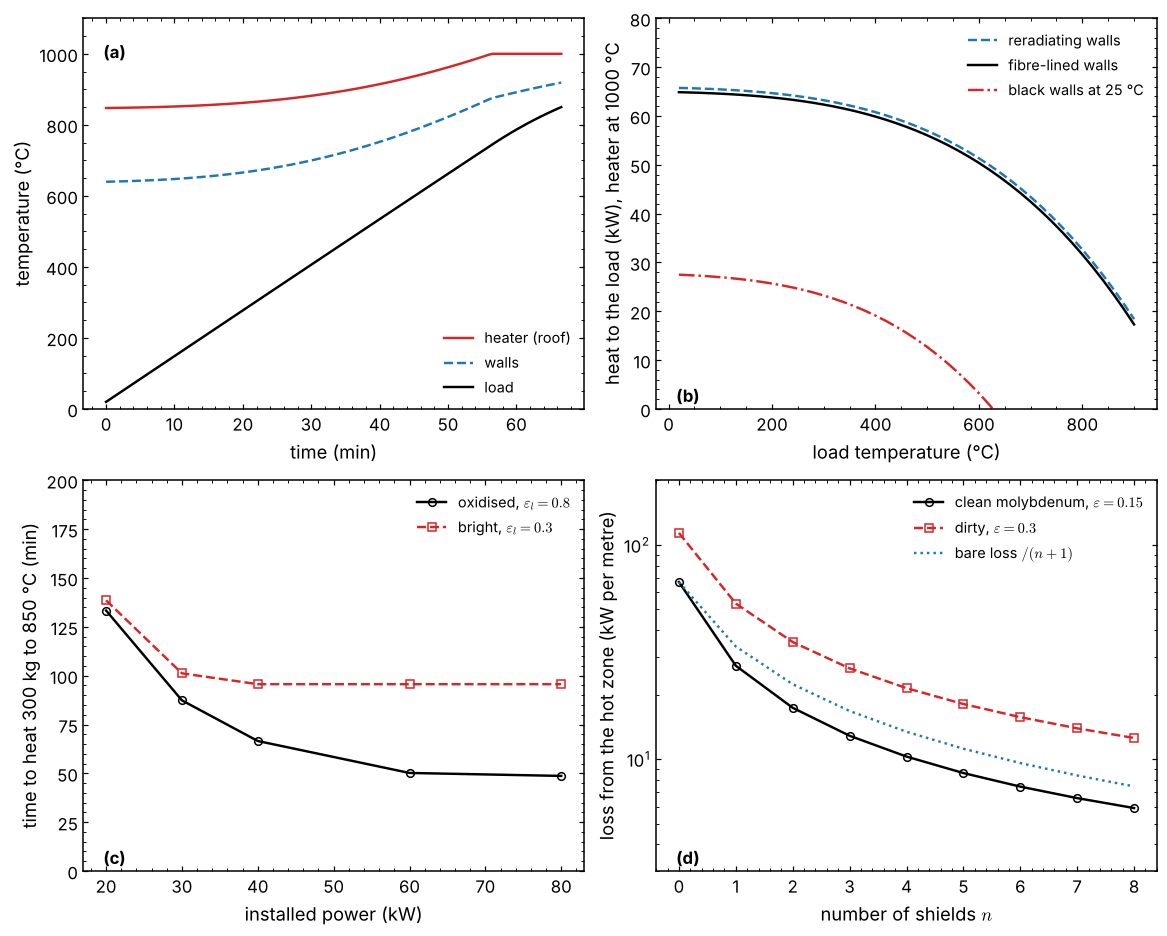

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

t_min = t_grid / 60
T_hist = base.sol(t_grid)[0]
states = [operate(T) for T in T_hist]
ax1.plot(t_min, [s["T"][0] - 273.15 for s in states], "C3-", label="heater (roof)")
ax1.plot(t_min, [s["T"][2] - 273.15 for s in states], "C0--", label="walls")
ax1.plot(t_min, T_hist - 273.15, "k-", label="load")
ax1.set_xlabel("time (min)")
ax1.set_ylabel("temperature (°C)")
ax1.set_ylim(0, 1100)
ax1.legend(loc="lower right")
panel_label(ax1, "(a)", x=0.04, y=0.94)

T_scan = np.linspace(293.15, 1173.15, 45)
for walls, style, label in (("reradiating", "C0--", "reradiating walls"), ("fibre", "k-", "fibre-lined walls"),
                            ("black", "C3-.", "black walls at 25 °C")):
    ax2.plot(T_scan - 273.15, [-furnace(T, T_heater=T_MAX, walls=walls)["Q"][1] / 1e3 for T in T_scan], style, label=label)
ax2.set_xlabel("load temperature (°C)")
ax2.set_ylabel("heat to the load (kW), heater at 1000 °C")
ax2.set_ylim(0, 80)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

P_list = np.array([20, 30, 40, 60, 80]) * 1e3
for eps_l, style, label in ((0.8, "ko-", r"oxidised, $\varepsilon_l = 0.8$"), (0.3, "C3s--", r"bright, $\varepsilon_l = 0.3$")):
    ax3.plot(P_list / 1e3, [heat_up(P_max=P, eps_load=eps_l).t_events[0][0] / 60 for P in P_list], style, ms=5,
             mfc="none", label=label)
ax3.set_xlabel("installed power (kW)")
ax3.set_ylabel("time to heat 300 kg to 850 °C (min)")
ax3.set_ylim(0, 200)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

for e, style, label in ((0.15, "ko-", r"clean molybdenum, $\varepsilon = 0.15$"), (0.3, "C3s--", r"dirty, $\varepsilon = 0.3$")):
    ax4.semilogy(n_sh, loss[e] / 1e3, style, ms=5, mfc="none", label=label)
ax4.semilogy(n_sh, loss[0.15][0] / (n_sh + 1) / 1e3, "C0:", label=r"bare loss $/(n+1)$")
ax4.set_xlabel("number of shields $n$")
ax4.set_ylabel("loss from the hot zone (kW per metre)")
ax4.set_ylim(3, 200)
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 13.2.** The two furnaces. (a) Temperatures of the heater, the walls and the load
during the heating of a batch to 850 °C, Eq. (13.14); the heater runs at full power until
the load reaches 743 °C and then at its 1000 °C limit. (b) Heat reaching the load from a heater at
1000 °C, for reradiating, fibre-lined and black cold walls. (c) Time to heat the batch to
850 °C against installed power, for oxidised and bright steel. (d) Heat lost from a vacuum
furnace hot zone at 1300 °C against the number of radiation shields, Eq. (13.15), with
the plane-layer rule $1/(n+1)$ for comparison.

The walls in (a) stay between the heater and the load throughout. In (b), the fibre-lined
walls deliver almost as much as ideal ones at every load temperature, while black cold
walls deliver less than half, and nothing at all above 627 °C, where the load starts to
lose heat to them. In (c), doubling the power from 40 to 80 kW saves only 18 minutes of
67, because the end of the cycle is limited by the element temperature, not the power; for
bright steel, more than 40 kW saves nothing, since the elements reach their limit almost at
once. In (d), the shields do better than $1/(n+1)$, because each new gap is lined with
molybdenum on both sides, whereas the bare gap faces the more emissive cold wall.

## 13.6 Checks

**View factors by numerical integration.** The four-fold integral (13.1) is evaluated by a
product Gauss–Legendre rule with $n$ nodes along each edge
(`reference.view_factor_gauss_rectangles`), for the roof and hearth (Eq. 13.5) and for the
hearth and a side wall (Eq. 13.6). In two dimensions, the integral
$F_{12} = (1/L_1)\int\int \cos\theta_1\cos\theta_2/(2r)\,ds_1ds_2$ is evaluated in the same
way (`reference.view_factor_gauss_strips`) for two strips hinged at an edge, and compared
with the crossed-string rule (13.7).

**View factors by Monte Carlo ray tracing.** Bundles of radiation leave random points of a
face in random diffuse directions, $\sin\theta = \sqrt{u_1}$ and $\phi = 2\pi u_2$ with
$u_1, u_2$ uniform on (0, 1), and are followed in a straight line to the face they hit
(`reference.mc_box_exchange`, after Howell and Perlmutter 1964). The fraction that lands on
each face estimates the view factor, with a statistical error that falls as
$1/\sqrt{N}$ for $N$ bundles.

**The whole furnace by ray tracing.** With reradiating walls, the same ray tracer follows
each bundle from the heater until it is absorbed: at the heater and load it is absorbed
with probability $\varepsilon$ and otherwise reflected diffusely, and at a wall it is always
reflected diffusely, which is what a reradiating diffuse surface does on average. This
needs no assumption of uniform radiosity on any surface. The fraction $f_{hl}$ of the
heater's emission absorbed by the load gives
$Q_{hl} = \varepsilon_hA_h\sigma(T_h^4 - T_l^4)\,f_{hl}$. It is compared with the network
when the walls are one zone, as in Section 13.4, and when each wall is cut into $n$
horizontal bands (`radiation.box_zone_view_factors`), whose view factors follow exactly from
Eqs. (13.5) and (13.6) by view-factor algebra.

In [8]:
roof = ([0, 0, Lz], [Lx, 0, 0], [0, Ly, 0])
hearth = ([0, 0, 0], [Lx, 0, 0], [0, Ly, 0])
wall_x0 = ([0, 0, 0], [0, Ly, 0], [0, 0, Lz])
n_gl = np.array([2, 4, 8, 16, 32, 64])
err_par = np.array([abs(reference.view_factor_gauss_rectangles(hearth, roof, n) - F6[0, 1]) for n in n_gl])
err_perp = np.array([abs(reference.view_factor_gauss_rectangles(hearth, wall_x0, n) - F6[0, 2]) for n in n_gl])
print("Gauss-Legendre, roof-hearth:  ", " ".join(f"{e:.1e}" for e in err_par))
print("Gauss-Legendre, hearth-wall:  ", " ".join(f"{e:.1e}" for e in err_perp))

# hinged strips of unit width at opening angle alpha: crossed strings against 2-D quadrature
alphas = np.radians(np.linspace(10, 170, 33))
F_cs, F_gl = [], []
for a in alphas:
    p0, p1, p2 = np.array([0.0, 0.0]), np.array([1.0, 0.0]), np.array([math.cos(a), math.sin(a)])
    F_cs.append(radiation.view_factor_crossed_strings(p0, p1, p0, p2))
    F_gl.append(reference.view_factor_gauss_strips(p0, p1, p0, p2, n=200))
F_cs, F_gl = np.array(F_cs), np.array(F_gl)
print(f"hinged strips: crossed strings against 1 - sin(alpha/2): {np.max(np.abs(F_cs - (1 - np.sin(alphas / 2)))):.1e};"
      f" against quadrature with 200 nodes: {np.max(np.abs(F_cs - F_gl)):.1e}")

N_mc = np.array([1e2, 1e3, 1e4, 1e5, 1e6]).astype(int)
rms = []
for N in N_mc:
    errs = [reference.mc_box_exchange(Lx, Ly, Lz, np.ones(6), 1, N, seed=s)[0] - F6[1] for s in range(8)]
    rms.append(np.sqrt(np.mean(np.square(errs))))
rms = np.array(rms)
frac, se = reference.mc_box_exchange(Lx, Ly, Lz, np.ones(6), 1, 4_000_000, seed=1)
print("Monte Carlo view factors from the roof, 4 million bundles:", " ".join(f"{f:.4f}" for f in frac))
print("   difference from Eqs. (13.5)-(13.6) in standard errors:", " ".join(f"{d:+.1f}" for d in (frac - F6[1])[[0, 2, 3, 4, 5]] / se[[0, 2, 3, 4, 5]]))

Gauss-Legendre, roof-hearth:   1.8e-02 5.4e-04 2.4e-07 4.9e-14 3.3e-16 7.2e-16
Gauss-Legendre, hearth-wall:   2.0e-01 1.5e-01 1.0e-01 6.5e-02 3.9e-02 2.3e-02
hinged strips: crossed strings against 1 - sin(alpha/2): 1.1e-16; against quadrature with 200 nodes: 2.5e-03


Monte Carlo view factors from the roof, 4 million bundles: 0.3416 0.0000 0.1996 0.1996 0.1299 0.1294
   difference from Eqs. (13.5)-(13.6) in standard errors: -0.6 +0.1 +0.2 +1.7 -1.2


In [9]:
T_h, T_l = T_MAX, 773.15
bands = np.array([1, 2, 4, 8, 16, 32, 64])
furn_check = {}
for eps_h, eps_l, seed in ((EPS_H, 0.8, 11), (1.0, 1.0, 12)):
    frac, se = reference.mc_box_exchange(Lx, Ly, Lz, [eps_l, eps_h, 0, 0, 0, 0], 1, 8_000_000, seed=seed)
    q_mc = eps_h * A6[1] * SIGMA * (T_h**4 - T_l**4) * frac[0]
    q_net = []
    for n in bands:
        Az, Fz = radiation.box_zone_view_factors(Lx, Ly, Lz, n)
        eps = np.full(len(Az), 0.5)
        eps[:2] = eps_l, eps_h
        T = np.full(len(Az), 1000.0)
        T[:2] = T_l, T_h
        Q = np.zeros(len(Az))
        Q[:2] = np.nan
        q_net.append(radiation.solve_radiosity_enclosure(Az, eps, Fz, T, Q=Q)["Q"][1])
    furn_check[(eps_h, eps_l)] = (q_mc, q_mc * se[0] / frac[0], np.array(q_net))
    print(f"heater eps {eps_h}, load eps {eps_l}: ray tracing {q_mc / 1e3:.3f} +- {q_mc * se[0] / frac[0] / 1e3:.3f} kW;"
          " network with 1, 4, 64 bands: " + ", ".join(f"{q_net[i] / 1e3:.3f}" for i in (0, 2, 6)) + " kW")
Az, Fz = radiation.box_zone_view_factors(Lx, Ly, Lz, 64)
eps = np.full(len(Az), 0.5)
eps[:2] = 0.8, EPS_H
T = np.full(len(Az), 1000.0)
T[:2] = T_l, T_h
Q = np.zeros(len(Az))
Q[:2] = np.nan
wall_T = radiation.solve_radiosity_enclosure(Az, eps, Fz, T, Q=Q)["T"][2:66] - 273.15
T_one = furnace(T_l, T_heater=T_MAX, walls="reradiating")["T"][2] - 273.15
print(f"wall x=0 with 64 bands: {wall_T[0]:.0f} C at the hearth, {wall_T[-1]:.0f} C at the roof (one zone: {T_one:.0f} C)")

heater eps 0.7, load eps 0.8: ray tracing 55.195 +- 0.015 kW; network with 1, 4, 64 bands: 56.965, 55.426, 55.301 kW


heater eps 1.0, load eps 1.0: ray tracing 79.377 +- 0.021 kW; network with 1, 4, 64 bands: 82.897, 79.678, 79.419 kW
wall x=0 with 64 bands: 747 C at the hearth, 872 C at the roof (one zone: 814 C)


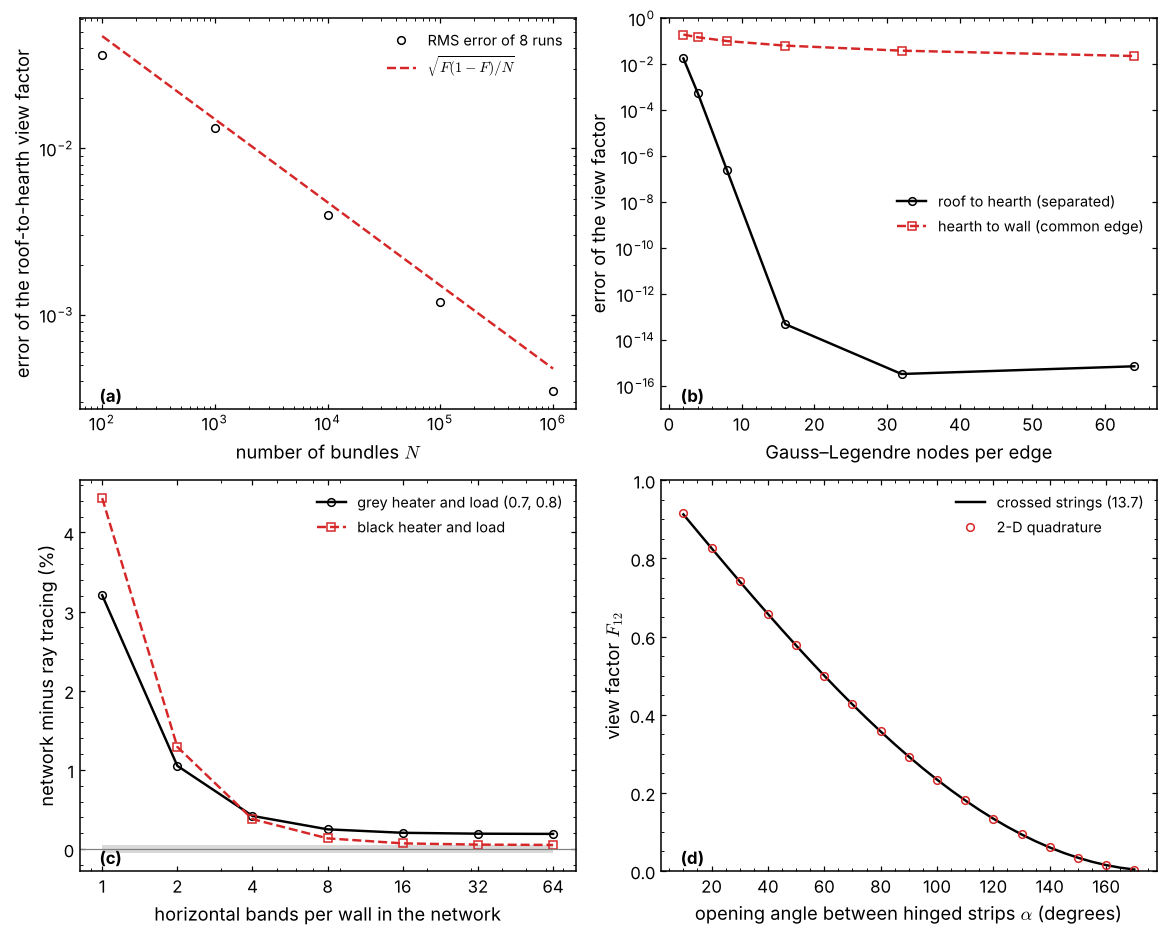

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

ax1.loglog(N_mc, rms, "ko", ms=5, mfc="none", label="RMS error of 8 runs")
ax1.loglog(N_mc, np.sqrt(F6[1, 0] * (1 - F6[1, 0]) / N_mc), "C3--", label=r"$\sqrt{F(1-F)/N}$")
ax1.set_xlabel("number of bundles $N$")
ax1.set_ylabel("error of the roof-to-hearth view factor")
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.06)

ax2.semilogy(n_gl, np.maximum(err_par, 1e-17), "ko-", ms=5, mfc="none", label="roof to hearth (separated)")
ax2.semilogy(n_gl, err_perp, "C3s--", ms=5, mfc="none", label="hearth to wall (common edge)")
ax2.set_xlabel("Gauss–Legendre nodes per edge")
ax2.set_ylabel("error of the view factor")
ax2.set_ylim(1e-17, 1)
ax2.legend(loc="center right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

for key, style, label in (((EPS_H, 0.8), "ko-", r"grey heater and load (0.7, 0.8)"), ((1.0, 1.0), "C3s--", "black heater and load")):
    q_mc, q_se, q_net = furn_check[key]
    ax3.semilogx(bands, 100 * (q_net / q_mc - 1), style, ms=5, mfc="none", label=label)
    ax3.fill_between(bands, -200 * q_se / q_mc, 200 * q_se / q_mc, color="0.85" if key[0] == 1.0 else "0.7", lw=0)
ax3.axhline(0, color="0.5", lw=0.8)
ax3.set_xticks(bands)
ax3.xaxis.set_major_formatter(plt.ScalarFormatter())
ax3.xaxis.set_minor_formatter(plt.NullFormatter())
ax3.set_xlabel("horizontal bands per wall in the network")
ax3.set_ylabel("network minus ray tracing (%)")
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

ax4.plot(np.degrees(alphas), F_cs, "k-", label="crossed strings (13.7)")
ax4.plot(np.degrees(alphas)[::2], F_gl[::2], "C3o", ms=5, mfc="none", label="2-D quadrature")
ax4.set_xlabel(r"opening angle between hinged strips $\alpha$ (degrees)")
ax4.set_ylabel(r"view factor $F_{12}$")
ax4.set_ylim(0, 1)
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 13.3.** Checks. (a) Root-mean-square error of the Monte Carlo view factor from
roof to hearth against the number of bundles, with the binomial standard error. (b) Error
of Gauss–Legendre quadrature of Eq. (13.1) against the exact results (13.5) and (13.6).
(c) Heat to the load from the radiosity network with the walls cut into horizontal bands,
relative to ray tracing of the whole furnace with 8 million bundles; the shaded bands are
two standard errors of the ray tracing. (d) View factor between two hinged strips of equal
width against their opening angle, by the crossed-string rule and by quadrature.

The Monte Carlo error follows $\sqrt{F(1-F)/N}$: a view factor to three decimals takes
about a million bundles, and each further digit a hundred times more. Gauss–Legendre
quadrature converges to machine precision with 16 nodes per edge when the two surfaces are
apart, but only slowly when they share an edge, where the integrand is singular; with
64 nodes it is still wrong in the second digit. Closed-form results such as Eq. (13.6) are
worth having. The crossed-string rule agrees with the exact $1 - \sin(\alpha/2)$ to
$10^{-16}$, and with quadrature to $3 \times 10^{-3}$, the slow convergence at the common
edge once more.

The furnace check is the most instructive. The one-zone network of Section 13.4 gives 3.2 %
more heat to the load than ray tracing. Cutting the walls into bands brings it to within
0.2 %, because the walls are far from uniform: with 64 bands, a side wall runs from 747 °C
at the hearth to 872 °C at the roof, around the one-zone value of 814 °C. With black heater
and load, the banded network and the ray tracing agree to 0.05 %, about two standard
errors; the remaining 0.2 % in the grey case comes from the radiosity of the roof and
hearth, which is not uniform either.

## 13.7 What to trust

* *Grey and diffuse.* Refractories and oxides are not grey: their emissivity changes with
  wavelength, and the radiation in a furnace shifts towards shorter wavelengths as it heats
  up. Metals reflect partly like mirrors. Both change the results by more than the 3 % of
  the zoning error, and spectral models or measured total exchange are needed when it
  matters.
* *Uniform radiosity.* One zone per surface overestimated the heat to the load by 3 %;
  zones must be small where the irradiation changes quickly, near corners and edges.
* *Heat stored in the lining.* 150 mm of fibre of density near 130 kg/m³ heated by a few
  hundred kelvin stores roughly a tenth of what the load takes up. The first batch after a
  cold start takes longer than the 67 minutes found here.
* *The load* is neither flat nor at one temperature: parts shade one another and their
  centres lag behind their surfaces (Chapter 5).
* *Radiation shields* also lose heat through their supports and ends, which this
  long-cylinder model leaves out.

## Summary

* The view factor (13.1) is the fraction of the radiation leaving one diffuse surface that
  reaches another. It obeys reciprocity (13.2) and summation (13.3), and closed forms
  (13.4)–(13.6), view-factor algebra and the crossed-string rule (13.7) give it for many
  shapes.
* For diffuse grey surfaces, each surface is a node of radiosity $J$ with a surface
  resistance (13.8), joined to the others by space resistances (13.9); the network gives one
  linear equation per surface, Eq. (13.10). Two-surface enclosures (13.11) and reradiating
  walls (13.12) follow.
* In an electric furnace, the reradiating walls carry half the heat to the load; with black
  cold walls the load would get less than a quarter as much. A 300 kg batch heats to 850 °C
  in 67 minutes at 40 kW, Eqs. (13.13)–(13.14).
* Radiation shields (13.15) divide the loss by about $n+1$; five clean molybdenum shields
  cut the loss of a vacuum hot zone from 67 to 8.6 kW per metre.
* Monte Carlo ray tracing and the banded network agree; the one-zone network is 3 % high.

## Exercises

Sample solutions are in [`solutions/part3_radiation/13_solutions.ipynb`](../../solutions/part3_radiation/13_solutions.ipynb).

1. **A blackbody reference.** Thermal cameras (Exercise 3 of Chapter 12) are calibrated
   against a cylindrical hole in an isothermal block, painted with $\varepsilon = 0.9$. Treat
   the inside of the hole as one surface and find its apparent emissivity, the radiation
   leaving the mouth divided by $\sigma T^4$ times the mouth area, for depths of 0.5 to
   6 diameters. Then cut the side wall into bands and compare. How deep must the hole be
   for a camera that looks at its base to see an apparent emissivity of 0.99?
2. **A thermocouple in a hot duct.** A sheathed thermocouple 3 mm across, with
   $\varepsilon = 0.8$, measures air at 500 °C flowing at 8 m/s across it in a duct whose
   walls are at 300 °C. What does it read? How much does a thin cylindrical shield 12 mm
   across with $\varepsilon = 0.3$ help, and one with $\varepsilon = 0.1$? (Use the
   Churchill–Bernstein correlation of Chapter 7 on both the probe and the shield.)
3. **Opening the door.** The front wall of the furnace of Section 13.4 (one of the
   0.8 m × 0.6 m walls) is its door. With the heater at 1000 °C and the load at 850 °C, how
   much heat leaves through the open door, which acts as a black surface at 25 °C? How much
   does the load lose in the 30 s the door is open, and how much does the temperature of a
   300 kg load fall?
4. **Inside the electronics cabinet.** The cabinet of Chapter 9 dissipates 623 W with its
   walls at 50 °C. Its equipment forms a box 1.2 m × 0.4 m × 0.4 m inside the
   1.6 m × 0.6 m × 0.6 m cabinet, with $\varepsilon = 0.9$. Find the surface temperature of
   the equipment, taking radiation to the walls as a two-surface enclosure (13.11) and
   natural convection from the equipment to the inside air, and from the air to the walls,
   with the Churchill–Chu correlation of Chapter 9. How much hotter does the equipment run if
   the inside of the cabinet is bare galvanised steel with $\varepsilon = 0.25$?

## Suggested references

* D. C. Hamilton and W. R. Morgan, "Radiant-interchange configuration factors", NACA
  Technical Note 2836 (1952).
* A. K. Oppenheim, "Radiation analysis by the network method", *Trans. ASME* **78**, 725
  (1956).
* J. R. Howell and M. Perlmutter, "Monte Carlo solution of thermal transfer through radiant
  media between gray walls", *J. Heat Transfer* **86**, 116 (1964).
* P.-F. Paradis, T. Ishikawa and S. Yoda, "Noncontact measurements of thermophysical
  properties of molybdenum at high temperatures", *Int. J. Thermophys.* **23**, 555 (2002).
* E. M. Sparrow, L. U. Albers and E. R. G. Eckert, "Thermal radiation characteristics of
  cylindrical enclosures", *J. Heat Transfer* **84**, 73 (1962).
* H. C. Hottel and A. F. Sarofim, *Radiative Transfer* (McGraw-Hill, 1967).
* J. R. Howell, M. P. Mengüç, K. Daun and R. Siegel, *Thermal Radiation Heat Transfer*,
  7th ed. (CRC Press, 2021).

---

**Previous:** [12. Black bodies and real surfaces](12_radiation_surfaces.ipynb) &nbsp;·&nbsp; **Next:** [14. Molecular diffusion](../part4_mass_transfer/14_molecular_diffusion.ipynb)